## Deep Learning Models: Development, Training and Evaluation

### Installing and using the necessary libraries

In [4]:
# Install the libraries required for data analysis and deep learning
%pip install pandas numpy matplotlib seaborn kagglehub scikit-learn tensorflow
# %pip install kagglehub

   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.8/384.1 MB 4.4 MB/s eta 0:01:28
   ---------------------------------------- 1.3/384.1 MB 3.7 MB/s eta 0:01:43
   ---------------------------------------- 1.8/384.1 MB 3.1 MB/s eta 0:02:05
   ---------------------------------------- 2.4/384.1 MB 3.0 MB/s eta 0:02:07
   ---------------------------------------- 3.1/384.1 MB 3.0 MB/s eta 0:02:06
   ---------------------------------------- 3.9/384.1 MB 3.1 MB/s eta 0:02:03
   ---------------------------------------- 4.5/384.1 MB 3.1 MB/s eta 0:02:04
    --------------------------------------- 5.2/384.1 MB 3.1 MB/s eta 0:02:03
    --------------------------------------- 5.8/384.1 MB 3.1 MB/s eta 0:02:03
    --------------------------------------- 6.6/384.1 MB 3.1 MB/s eta 0:02:01
    --------------------------------------- 7.3/384.1 MB 3.1 MB/s eta 0:02:00
    --------------------------------------- 7.9/384.1 MB 3.1 MB/s eta 0

In [5]:
# DATA MANIPULATION AND NUMERICAL COMPUTATION

import pandas as pd
import numpy as np

# DATA VISUALIZATION

import matplotlib.pyplot as plt
import seaborn as sns

# DATASET ACCESS AND DOWNLOAD

import kagglehub
from kagglehub import KaggleDatasetAdapter

# DATA PREPROCESSING

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# DEEP LEARNING MODEL ARCHITECTURE

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# MODEL OPTIMIZATION AND TRAINING

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# MODEL EVALUATION METRICS

from sklearn.metrics import mean_squared_error, r2_score

# LIBRARY VERSION INFORMATION

import sklearn
import tensorflow as tf

print("All libraries imported successfully!")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Scikit-learn version: {sklearn.__version__}")
print(f"TensorFlow version: {tf.__version__}")

All libraries imported successfully!
Pandas version: 3.0.3
NumPy version: 2.4.6
Scikit-learn version: 1.9.0
TensorFlow version: 2.22.0-rc0


### Dataset do Kaggle

### Houseprices

In [6]:
pip install kagglehub[pandas-datasets]

Note: you may need to restart the kernel to use updated packages.


In [7]:
# DEFINE THE DATASET FILE PATH

# Specify the name of the CSV file to load
file_path = "train.csv"

# LOAD THE DATASET FROM KAGGLE

# Load the dataset into a pandas DataFrame
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "lespin/house-prices-dataset",
    file_path,
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

# DISPLAY THE FIRST SIX RECORDS

print("First six records of the dataset:")
display(df.head(6))

100%|██████████| 450k/450k [00:00<00:00, 662kB/s]


First six records of the dataset:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
5,6,50,RL,85.0,14115,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,Shed,700,10,2009,WD,Normal,143000


In [8]:
# 1. INSPECT THE DATASET STRUCTURE

# Display column names, data types, and non-null counts
df.info()

# IDENTIFY FEATURES WITH A HIGH PROPORTION OF MISSING VALUES

# The following features contain substantial missing data:
# Alley         : 91 non-null values
# MasVnrType    : 588 non-null values
# FireplaceQu   : 770 non-null values
# PoolQC        : 7 non-null values
# Fence         : 281 non-null values
# MiscFeature   : 54 non-null values

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [9]:
# 3. CALCULATE MISSING VALUES AND THEIR PERCENTAGES

# Calculate the number of missing values in each column
missing_values = df.isnull().sum()

# Calculate the percentage of missing values in each column
missing_percentage = (missing_values / len(df)) * 100

# Create a summary table of missing values
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage (%)": missing_percentage
})

# Keep only columns containing missing values
missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values(
    by="Missing Percentage (%)",
    ascending=False
)

# Display the missing-value summary
display(missing_summary.round(2))

,Missing Values,Missing Percentage (%)
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


In [10]:
# DROP FEATURES WITH A HIGH PROPORTION OF MISSING VALUES

# Define the columns to remove from the dataset
cols_to_drop = [
    "Alley",
    "MasVnrType",
    "FireplaceQu",
    "PoolQC",
    "Fence",
    "MiscFeature"
]

# Drop the specified columns if they exist in the dataset
df = df.drop(columns=cols_to_drop, errors="ignore")

# Display the number of remaining columns
print("Number of remaining columns:", df.shape[1])

# Inspect the updated dataset structure
df.info()


# HANDLE MISSING VALUES IN NUMERICAL FEATURES

# Select all numerical columns
numeric_cols = df.select_dtypes(include=["number"]).columns

# Replace missing numerical values with the median of each column
df[numeric_cols] = df[numeric_cols].fillna(
    df[numeric_cols].median()
)


# HANDLE MISSING VALUES IN CATEGORICAL FEATURES

# Forward-fill missing values using the previous valid observation
df = df.ffill()

# Inspect the dataset after missing-value treatment
df.info()

Number of remaining columns: 75
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 75 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   LotShape       1460 non-null   str    
 7   LandContour    1460 non-null   str    
 8   Utilities      1460 non-null   str    
 9   LotConfig      1460 non-null   str    
 10  LandSlope      1460 non-null   str    
 11  Neighborhood   1460 non-null   str    
 12  Condition1     1460 non-null   str    
 13  Condition2     1460 non-null   str    
 14  BldgType       1460 non-null   str    
 15  HouseStyle     1460 non-null   str    
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   

In [18]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,69.863699,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.117123,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,22.027677,9981.264932,1.382997,1.112799,30.202904,20.645407,180.731373,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,60.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,79.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,164.250000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


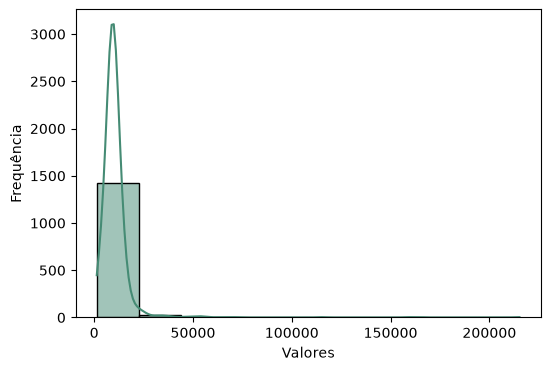

In [20]:
plt.figure(figsize=(6, 4))
sns.histplot(df['LotArea'], kde=True, bins=10, color='#458b74')
#plt.title('Product Price Distribution')
plt.xlabel('Valores') #texto
plt.ylabel('Frequência')
# plt.savefig("histograma_2.png", dpi=600)
plt.show()

In [16]:
# HANDLE MISSING VALUES IN CATEGORICAL FEATURES

# Select categorical columns
categorical_cols = df.select_dtypes(
    include=["object", "category", "string"]
).columns

# Replace missing categorical values with the most frequent category
for col in categorical_cols:
    if df[col].isnull().any():
        mode_values = df[col].mode(dropna=True)

        if not mode_values.empty:
            df[col] = df[col].fillna(mode_values.iloc[0])
        else:
            df[col] = df[col].fillna("Missing")

# Check whether any missing values remain
print("Total missing values:", df.isnull().sum().sum())

# df[categorical_cols] = df[categorical_cols].fillna(df[categorical_cols].mode())

# df = df.ffill()

df.info()

Total missing values: 0
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 75 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1460 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   LotShape       1460 non-null   str    
 7   LandContour    1460 non-null   str    
 8   Utilities      1460 non-null   str    
 9   LotConfig      1460 non-null   str    
 10  LandSlope      1460 non-null   str    
 11  Neighborhood   1460 non-null   str    
 12  Condition1     1460 non-null   str    
 13  Condition2     1460 non-null   str    
 14  BldgType       1460 non-null   str    
 15  HouseStyle     1460 non-null   str    
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  


In [17]:
# ENCODE CATEGORICAL FEATURES

# Convert categorical variables into binary dummy variables
df = pd.get_dummies(df, drop_first=False)

# Display the dataset structure after encoding
df.info()

# Display the first five records
display(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Columns: 268 entries, Id to SaleCondition_Partial
dtypes: bool(230), float64(3), int64(35)
memory usage: 761.5 KB


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,1,60,65.0,8450,7,5,2003,2003,196.0,706,...,False,False,False,True,False,False,False,False,True,False
1,2,20,80.0,9600,6,8,1976,1976,0.0,978,...,False,False,False,True,False,False,False,False,True,False
2,3,60,68.0,11250,7,5,2001,2002,162.0,486,...,False,False,False,True,False,False,False,False,True,False
3,4,70,60.0,9550,7,5,1915,1970,0.0,216,...,False,False,False,True,True,False,False,False,False,False
4,5,60,84.0,14260,8,5,2000,2000,350.0,655,...,False,False,False,True,False,False,False,False,True,False


In [33]:
# SEPARATE PREDICTORS AND TARGET VARIABLE

# Remove the target variable and identifier from the predictors
x = df.drop(columns=["SalePrice", "Id"])

# Define the target variable
y = df["SalePrice"]

# Display the dimensions of the predictors and target
print("Predictor matrix shape:", x.shape)
print("Target vector shape:", y.shape)

Predictor matrix shape: (1460, 266)
Target vector shape: (1460,)


In [36]:
# STANDARDIZE THE PREDICTOR VARIABLES

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_scaled = scaler.fit_transform(X)
    

In [37]:
# LOAD THE KAGGLE TEST DATASET

# Specify the test dataset filename
file_path = "test.csv"

# Load the test dataset from Kaggle
df_test = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "lespin/house-prices-dataset",
    file_path,
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

# Display the first six records
print("First six records of the test dataset:")
display(df_test.head(6))

# Inspect the dataset structure
df_test.info()

First six records of the test dataset:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal
5,1466,60,RL,75.0,10000,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal


<class 'pandas.DataFrame'>
RangeIndex: 1459 entries, 0 to 1458
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1459 non-null   int64  
 1   MSSubClass     1459 non-null   int64  
 2   MSZoning       1455 non-null   str    
 3   LotFrontage    1232 non-null   float64
 4   LotArea        1459 non-null   int64  
 5   Street         1459 non-null   str    
 6   Alley          107 non-null    str    
 7   LotShape       1459 non-null   str    
 8   LandContour    1459 non-null   str    
 9   Utilities      1457 non-null   str    
 10  LotConfig      1459 non-null   str    
 11  LandSlope      1459 non-null   str    
 12  Neighborhood   1459 non-null   str    
 13  Condition1     1459 non-null   str    
 14  Condition2     1459 non-null   str    
 15  BldgType       1459 non-null   str    
 16  HouseStyle     1459 non-null   str    
 17  OverallQual    1459 non-null   int64  
 18  OverallCond    1459

In [38]:
# REMOVE FEATURES WITH A HIGH PROPORTION OF MISSING VALUES

# Define the columns to remove from the test dataset
cols_to_drop = [
    "Alley",
    "MasVnrType",
    "FireplaceQu",
    "PoolQC",
    "Fence",
    "MiscFeature"
]

# Remove the specified columns if they exist
df_test = df_test.drop(
    columns=cols_to_drop,
    errors="ignore"
)

# Display the number of remaining columns
print("Number of remaining columns:", df_test.shape[1])

# Inspect the structure of the test dataset
df_test.info()

Number of remaining columns: 74
<class 'pandas.DataFrame'>
RangeIndex: 1459 entries, 0 to 1458
Data columns (total 74 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1459 non-null   int64  
 1   MSSubClass     1459 non-null   int64  
 2   MSZoning       1455 non-null   str    
 3   LotFrontage    1232 non-null   float64
 4   LotArea        1459 non-null   int64  
 5   Street         1459 non-null   str    
 6   LotShape       1459 non-null   str    
 7   LandContour    1459 non-null   str    
 8   Utilities      1457 non-null   str    
 9   LotConfig      1459 non-null   str    
 10  LandSlope      1459 non-null   str    
 11  Neighborhood   1459 non-null   str    
 12  Condition1     1459 non-null   str    
 13  Condition2     1459 non-null   str    
 14  BldgType       1459 non-null   str    
 15  HouseStyle     1459 non-null   str    
 16  OverallQual    1459 non-null   int64  
 17  OverallCond    1459 non-null   

In [39]:
# HANDLE MISSING VALUES IN NUMERICAL FEATURES

# Identify numerical columns
numeric_cols = df_test.select_dtypes(include=["number"]).columns

# Impute missing numerical values using each column's median
df_test[numeric_cols] = df_test[numeric_cols].fillna(
    df_test[numeric_cols].median()
)

# For the remaining categorical columns, we can use `ffill` as before
df_test = df_test.ffill()

df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 1459 entries, 0 to 1458
Data columns (total 74 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1459 non-null   int64  
 1   MSSubClass     1459 non-null   int64  
 2   MSZoning       1459 non-null   str    
 3   LotFrontage    1459 non-null   float64
 4   LotArea        1459 non-null   int64  
 5   Street         1459 non-null   str    
 6   LotShape       1459 non-null   str    
 7   LandContour    1459 non-null   str    
 8   Utilities      1459 non-null   str    
 9   LotConfig      1459 non-null   str    
 10  LandSlope      1459 non-null   str    
 11  Neighborhood   1459 non-null   str    
 12  Condition1     1459 non-null   str    
 13  Condition2     1459 non-null   str    
 14  BldgType       1459 non-null   str    
 15  HouseStyle     1459 non-null   str    
 16  OverallQual    1459 non-null   int64  
 17  OverallCond    1459 non-null   int64  
 18  YearBuilt      1459

In [40]:
# HANDLE MISSING VALUES IN CATEGORICAL FEATURES

# Identify categorical columns
categorical_cols = df_test.select_dtypes(
    include=["object", "category"]
).columns

# Impute missing categorical values using each column's mode
for col in categorical_cols:
    if df_test[col].isna().any():
        mode_values = df_test[col].mode(dropna=True)

        if not mode_values.empty:
            df_test[col] = df_test[col].fillna(mode_values.iloc[0])

# Inspect the dataset after missing-value imputation
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 1459 entries, 0 to 1458
Data columns (total 74 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1459 non-null   int64  
 1   MSSubClass     1459 non-null   int64  
 2   MSZoning       1459 non-null   str    
 3   LotFrontage    1459 non-null   float64
 4   LotArea        1459 non-null   int64  
 5   Street         1459 non-null   str    
 6   LotShape       1459 non-null   str    
 7   LandContour    1459 non-null   str    
 8   Utilities      1459 non-null   str    
 9   LotConfig      1459 non-null   str    
 10  LandSlope      1459 non-null   str    
 11  Neighborhood   1459 non-null   str    
 12  Condition1     1459 non-null   str    
 13  Condition2     1459 non-null   str    
 14  BldgType       1459 non-null   str    
 15  HouseStyle     1459 non-null   str    
 16  OverallQual    1459 non-null   int64  
 17  OverallCond    1459 non-null   int64  
 18  YearBuilt      1459

C:\Users\sanch\AppData\Local\Temp\ipykernel_18804\1781134293.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_test.select_dtypes(


In [41]:
# ENCODE CATEGORICAL FEATURES

# Convert categorical variables into one-hot encoded features
df_test_dummies = pd.get_dummies(df_test, dtype=int)

# Inspect the encoded dataset
df_test_dummies.info()

<class 'pandas.DataFrame'>
RangeIndex: 1459 entries, 0 to 1458
Columns: 251 entries, Id to SaleCondition_Partial
dtypes: float64(11), int64(240)
memory usage: 2.8 MB


In [42]:
# PREPARE THE TEST FEATURES

# Preserve the test sample identifiers
test_ids = df_test_dummies["Id"].copy()

# Remove the identifier from the predictor matrix
x_t = df_test_dummies.drop(columns=["Id"], errors="ignore")

# Align the test features with the training features
# Add missing training columns and remove extra test columns
x_t = x_t.reindex(columns=X.columns, fill_value=0)

In [43]:
# SCALE THE TEST FEATURES

# Use the scaler fitted on the training data
# Do not fit a new scaler on the test dataset
x_test_scaled = scaler.transform(x_t)

print("Test data preprocessing and scaling completed successfully.")
print("Test feature matrix shape:", x_test_scaled.shape)

Test data preprocessing and scaling completed successfully.
Test feature matrix shape: (1459, 266)


### SPLIT THE DATA INTO TRAINING AND VALIDATION SETS

In [44]:
# Split the dataset into training and validation sets
x_train, x_test, y_train, y_test = train_test_split(
    x_scaled,
    y,
    test_size=0.2,
    random_state=42
)

# Display the number of samples in each set
print("Training and validation split completed successfully!")
print(f"Training samples: {x_train.shape[0]}")
print(f"Validation samples: {x_test.shape[0]}")

Training and validation split completed successfully!
Training samples: 1168
Validation samples: 292


### DEFINE THE NEURAL NETWORK ARCHITECTURE

In [45]:
# Initialize the sequential neural network

model = Sequential([
    Dense(128, activation="relu", input_shape=(x_train.shape[1],)),
    Dense(64, activation="relu"),
    Dense(1, activation="linear")  # Output layer for regression
])

C:\Users\sanch\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### COMPILE THE MODEL

In [48]:
# Configure the optimizer, loss function, and evaluation metric
model.compile(
    optimizer=Adam(learning_rate=0.005),
    loss="mean_squared_error",
    metrics=["mae"]
)

### TRAIN THE NEURAL NETWORK

In [49]:
# Train the model and monitor its validation performance

history = model.fit(
    x_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 39118548992.0000 - mae: 181464.0625 - val_loss: 37715148800.0000 - val_mae: 180824.5000
Epoch 2/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 38555000832.0000 - mae: 180284.2500 - val_loss: 36399820800.0000 - val_mae: 177964.9688
Epoch 3/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 35585040384.0000 - mae: 173867.4844 - val_loss: 31496151040.0000 - val_mae: 166645.5156
Epoch 4/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 27882014720.0000 - mae: 155160.9062 - val_loss: 21887950848.0000 - val_mae: 139905.0469
Epoch 5/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 16828425216.0000 - mae: 119571.7266 - val_loss: 12178130944.0000 - val_mae: 98168.1250
Epoch 6/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9164928000.0000 - mae: 81244.9922 - val_loss: 8137348608.0000 - val_mae: 75123.3281
Epoch 7/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6250471936.0000 - mae: 64763.0820 - val_loss: 6195977728.0000 -

### EVALUATE MODEL PERFORMANCE

In [50]:
# Evaluate the model on the validation set
loss, mae = model.evaluate(x_test, y_test, verbose=0)

# Generate predictions
y_pred = model.predict(x_test, verbose=0).flatten()

# Calculate additional regression metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display evaluation metrics
print("Model Evaluation Results")
print("-" * 40)
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Coefficient of Determination (R²): {r2:.4f}")

Model Evaluation Results
----------------------------------------
Mean Squared Error (MSE): 1475062656.00
Root Mean Squared Error (RMSE): 38406.54
Mean Absolute Error (MAE): 24288.17
Coefficient of Determination (R²): 0.8077


### VISUALIZE MODEL PERFORMANCE

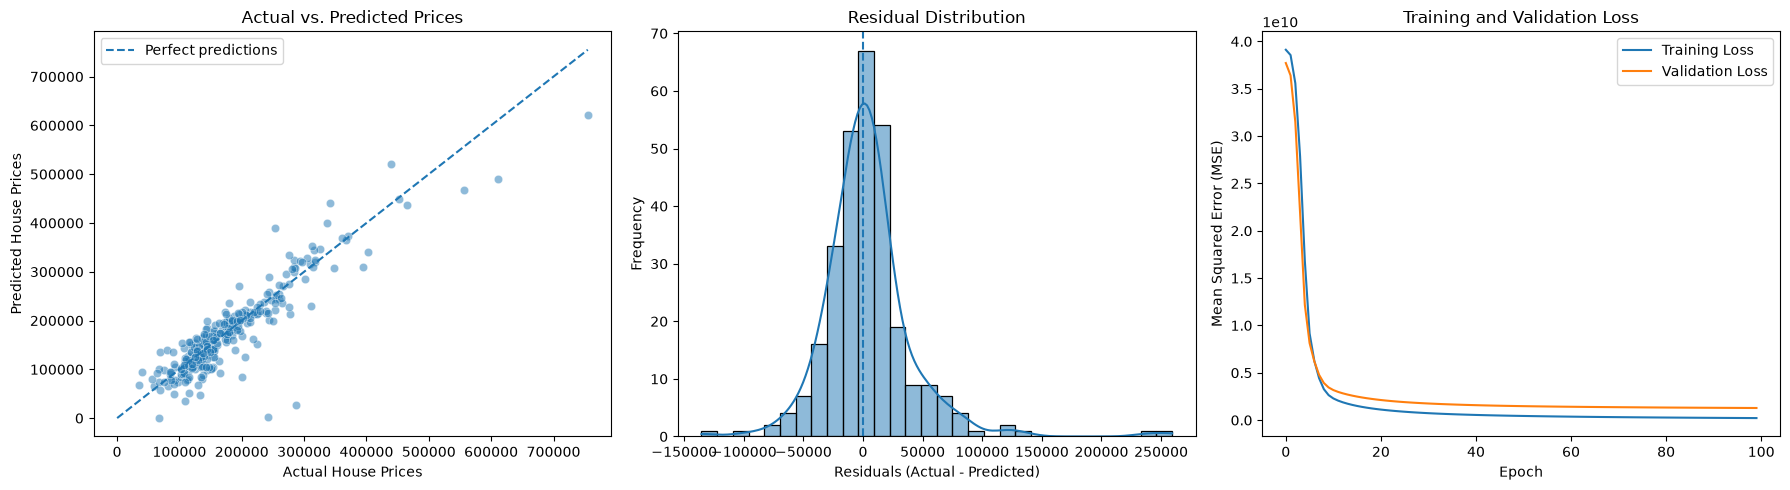

In [51]:
# Convert the target values to one-dimensional arrays
y_test_array = np.asarray(y_test).flatten()
residuals = y_test_array - y_pred

# Create a figure with three subplots
plt.figure(figsize=(18, 5))

# ------------------------------------------------------------
# Plot 1: Actual vs. Predicted House Prices
# ------------------------------------------------------------
plt.subplot(1, 3, 1)

sns.scatterplot(
    x=y_test_array,
    y=y_pred,
    alpha=0.5
)

# Add a reference line representing perfect predictions
min_value = min(y_test_array.min(), y_pred.min())
max_value = max(y_test_array.max(), y_pred.max())
plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Perfect predictions"
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs. Predicted Prices")
plt.legend()

# ------------------------------------------------------------
# Plot 2: Residual Distribution
# ------------------------------------------------------------
plt.subplot(1, 3, 2)

sns.histplot(
    residuals,
    kde=True,
    bins=30
)

plt.axvline(0, linestyle="--")
plt.xlabel("Residuals (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Residual Distribution")

# ------------------------------------------------------------
# Plot 3: Training and Validation Loss
# ------------------------------------------------------------
plt.subplot(1, 3, 3)

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Training and Validation Loss")
plt.legend()

# Adjust the layout and display the plots
plt.tight_layout()
plt.show()

### OPTIMIZE AND REGULARIZE THE NEURAL NETWORK

In [53]:
# Define the neural network architecture
model_b = Sequential([
    Dense(128, activation="relu", input_shape=(x_train.shape[1],)),
    Dropout(0.5),

    Dense(64, activation="relu"),
    Dropout(0.5),

    Dense(32, activation="relu"),
    Dropout(0.5),

    Dense(1, activation="linear")
])


# ============================================================
# 8. COMPILE THE MODEL
# ============================================================

# Configure the optimizer, loss function, and evaluation metric
model_b.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mean_squared_error",
    metrics=["mae"]
)


# ============================================================
# 9. CONFIGURE EARLY STOPPING
# ============================================================

# Stop training when validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)


# ============================================================
# 10. TRAIN THE REGULARIZED MODEL
# ============================================================

# Train the model with early stopping
history_b = model_b.fit(
    x_train,
    y_train,
    epochs=200,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

C:\Users\sanch\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 103ms/step - loss: 39146049536.0000 - mae: 181524.0156 - val_loss: 37839982592.0000 - val_mae: 181096.3750
Epoch 2/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 39139680256.0000 - mae: 181507.9688 - val_loss: 37825216512.0000 - val_mae: 181060.7969
Epoch 3/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 39092899840.0000 - mae: 181403.1406 - val_loss: 37720932352.0000 - val_mae: 180828.5625
Epoch 4/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 90ms/step - loss: 38825627648.0000 - mae: 180831.8438 - val_loss: 37221638144.0000 - val_mae: 179748.7500
Epoch 5/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 37811273728.0000 - mae: 178721.0938 - val_loss: 35672395776.0000 - val_mae: 176368.4219
Epoch 6/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 35225497600.0000 - mae: 173093.1719 - val_loss: 32266731520.0000 - val_mae: 168567.9531
Epoch 7/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 30696685568.0000 - mae: 162252.6250 - val_loss: 267

### EVALUATE THE REGULARIZED MODEL

In [54]:
# Evaluate the model on the validation set

loss_b, mae_b = model_b.evaluate(
    x_test,
    y_test,
    verbose=0
)

# Generate predictions
y_pred_b = model_b.predict(
    x_test,
    verbose=0
).flatten()

# Calculate additional regression metrics
y_test_array = np.asarray(y_test).flatten()

mse_b = mean_squared_error(y_test_array, y_pred_b)
rmse_b = np.sqrt(mse_b)
r2_b = r2_score(y_test_array, y_pred_b)

# Display evaluation results
print("Regularized Neural Network - Evaluation Results")
print("-" * 50)
print(f"Mean Squared Error (MSE): {mse_b:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse_b:.2f}")
print(f"Mean Absolute Error (MAE): {mae_b:.2f}")
print(f"Coefficient of Determination (R²): {r2_b:.4f}")
print(f"Training epochs completed: {len(history_b.history['loss'])}")

Regularized Neural Network - Evaluation Results
--------------------------------------------------
Mean Squared Error (MSE): 1970410368.00
Root Mean Squared Error (RMSE): 44389.30
Mean Absolute Error (MAE): 28697.75
Coefficient of Determination (R²): 0.7431
Training epochs completed: 171


### VISUALIZE THE REGULARIZED MODEL'S PERFORMANCE

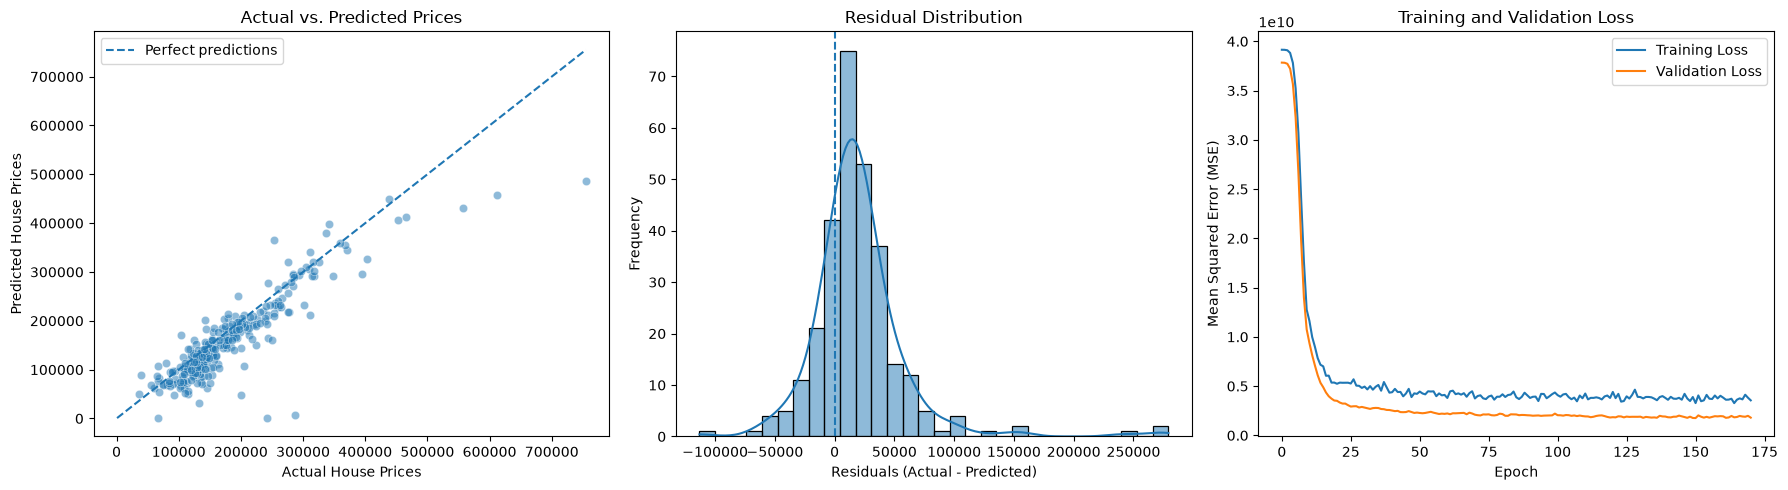

In [55]:
# Convert actual and predicted values to one-dimensional arrays

y_test_array = np.asarray(y_test).flatten()
y_pred_flat = np.asarray(y_pred_b).flatten()

# Calculate residuals
residuals = y_test_array - y_pred_flat

# Create a figure with three subplots
plt.figure(figsize=(18, 5))

# ------------------------------------------------------------
# Plot 1: Actual vs. Predicted House Prices
# ------------------------------------------------------------
plt.subplot(1, 3, 1)

sns.scatterplot(
    x=y_test_array,
    y=y_pred_flat,
    alpha=0.5
)

# Add a reference line for perfect predictions
min_value = min(y_test_array.min(), y_pred_flat.min())
max_value = max(y_test_array.max(), y_pred_flat.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Perfect predictions"
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs. Predicted Prices")
plt.legend()

# ------------------------------------------------------------
# Plot 2: Residual Distribution
# ------------------------------------------------------------
plt.subplot(1, 3, 2)

sns.histplot(
    residuals,
    kde=True,
    bins=30
)

plt.axvline(0, linestyle="--")
plt.xlabel("Residuals (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Residual Distribution")

# ------------------------------------------------------------
# Plot 3: Training and Validation Loss
# ------------------------------------------------------------
plt.subplot(1, 3, 3)

plt.plot(
    history_b.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_b.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Training and Validation Loss")
plt.legend()

# Adjust the layout and display the plots
plt.tight_layout()
plt.show()

### HYPERPARAMETER OPTIMIZATION

In [57]:
%pip install keras-tuner

import keras_tuner as kt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   -------- ------------------------------- 0.5/2.4 MB 4.6 MB/s eta 0:00:01
   ------------- -------------------------- 0.8/2.4 MB 2.5 MB/s eta 0:00:01
   ----------------- ---------------------- 1.0/2.4 MB 2.3 MB/s eta 0:00:01
   ----------------- ---------------------- 1.0/2.4 MB 2.3 MB/s eta 0:00:01
   --------------------- ------------------ 1.3/2.4 MB 1.3 MB/s eta 0:00:01
   --------------------- ------------------ 1.3/2.4 MB 1.3 MB/s eta 0:00:01
   -------------------------- ------------- 1.6/2.4 MB 1.0 MB/s eta 0:00:01
   -------------------------- ------------- 1.6/2.4 MB 1.0 MB/s eta 0:00:01
   -------------------------- ------------- 1.6/2.4 MB 1.0 MB/s eta 0:00:01
   -------------------------- ------------- 1.6/2.4 MB 1.0 MB/s eta 0:00:01
   ------------------------------ --------- 1.8/2.4 MB 720.9 kB/s eta 0:00:01
   ------------------------------ --------- 1.8/2.4 MB 720.9 kB/s eta 0:00:01
   ------------

In [59]:
%pip install tensorboard

import tensorflow as tf
import tensorboard
import keras_tuner as kt

print("TensorFlow version:", tf.__version__)
print("TensorBoard version:", tensorboard.__version__)
print("Keras Tuner version:", kt.__version__)
print("All required packages imported successfully!")

   ---------------------------------------- 0.0/5.5 MB ? eta -:--:--
   --- ------------------------------------ 0.5/5.5 MB 3.2 MB/s eta 0:00:02
   --------- ------------------------------ 1.3/5.5 MB 3.2 MB/s eta 0:00:02
   ------------- -------------------------- 1.8/5.5 MB 3.0 MB/s eta 0:00:02
   ----------------- ---------------------- 2.4/5.5 MB 3.0 MB/s eta 0:00:02
   ---------------------- ----------------- 3.1/5.5 MB 3.1 MB/s eta 0:00:01
   -------------------------- ------------- 3.7/5.5 MB 3.1 MB/s eta 0:00:01
   -------------------------------- ------- 4.5/5.5 MB 3.1 MB/s eta 0:00:01
   -------------------------------------- - 5.2/5.5 MB 3.1 MB/s eta 0:00:01
   ---------------------------------------- 5.5/5.5 MB 3.0 MB/s  0:00:01

   -------------------- ------------------- 1/2 [tensorboard]
   -------------------- ------------------- 1/2 [tensorboard]
   -------------------- ------------------- 1/2 [tensorboard]
   -------------------- ------------------- 1/2 [tensorboard]
 

In [60]:
# Define the neural network search space

def build_model(hp):

    model = Sequential()

    # Select the number of hidden layers
    num_layers = hp.Int(
        "num_layers",
        min_value=1,
        max_value=3
    )

    for i in range(num_layers):

        units = hp.Choice(
            f"units_{i}",
            values=[32, 64, 128, 256]
        )

        # Select the L2 regularization strength
        l2_strength = hp.Choice(
            "l2_strength",
            values=[0.0, 0.0001, 0.001]
        )

        if i == 0:
            model.add(
                Dense(
                    units,
                    activation="relu",
                    input_shape=(x_train.shape[1],),
                    kernel_regularizer=l2(l2_strength)
                )
            )
        else:
            model.add(
                Dense(
                    units,
                    activation="relu",
                    kernel_regularizer=l2(l2_strength)
                )
            )

        # Tune the dropout rate
        dropout_rate = hp.Choice(
            "dropout_rate",
            values=[0.0, 0.2, 0.3, 0.5]
        )

        if dropout_rate > 0:
            model.add(Dropout(dropout_rate))

    # Regression output layer
    model.add(Dense(1, activation="linear"))

    # Tune the learning rate
    learning_rate = hp.Choice(
        "learning_rate",
        values=[0.0001, 0.0005, 0.001, 0.003]
    )

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="mean_squared_error",
        metrics=["mae"]
    )

    return model

In [ ]:

# Configure the hyperparameter search
tuner = kt.RandomSearch(
    hypermodel=build_model,
    objective="val_loss",
    max_trials=25,
    executions_per_trial=1,
    directory="hyperparameter_tuning",
    project_name="house_price_regression",
    overwrite=True,
    seed=42
)


# Stop training when validation loss stops improving
early_stopping_tuning = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)


# Search for the best hyperparameter configuration
tuner.search(
    x_train,
    y_train,
    epochs=150,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping_tuning],
    verbose=1
)

Trial 1 Complete [00h 01m 27s]
val_loss: 1560363520.0

Best val_loss So Far: 1560363520.0
Total elapsed time: 00h 01m 27s

Search: Running Trial #2

Value             |Best Value So Far |Hyperparameter
2                 |2                 |num_layers
128               |32                |units_0
0                 |0.0001            |l2_strength
0.2               |0.2               |dropout_rate
0.0001            |0.003             |learning_rate
256               |32                |units_1

Epoch 1/150
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 65ms/step - loss: 39146610688.0000 - mae: 181525.5312 - val_loss: 37841494016.0000 - val_mae: 181100.3125
Epoch 2/150
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 39145918464.0000 - mae: 181523.6562 - val_loss: 37840814080.0000 - val_mae: 181098.4688
Epoch 3/150
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 39145115648.0000 - mae: 181521.4531 - val_loss: 37839970304.0000 - val_mae: 181096.2188
Epoch 4/150
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 

### RETRIEVE THE BEST HYPERPARAMETERS

In [ ]:
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Best hyperparameter configuration")
print("-" * 40)

for parameter, value in best_hp.values.items():
    print(f"{parameter}: {value}")


# Retrieve the best-performing model
best_model = tuner.get_best_models(num_models=1)[0]